# Green AI Data Center: Data Preparation

## Project Overview
This notebook focuses on preparing the Green AI Data Center
Telemetry Dataset for statistical analysis and modeling.

The objective of this project is to evaluate and compare multiple machine learning classification algorithms to identify the model that most effectively classifies data center energy efficiency. The selected model will be proposed as an efficiency monitoring tool for business and environmental stakeholders, supporting operational decisions and sustainability initiatives.

Dataset: Green AI Data Center Telemetry Dataset
Source: Deep Joshi (2026), Kaggle

In [49]:
print("Kernel is working")

Kernel is working


In [50]:
### Libraries here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pip
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import joblib
from pathlib import Path
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
%pip install xgboost
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from statsmodels.stats.proportion import proportion_confint
import seaborn as sns

Note: you may need to restart the kernel to use updated packages.


In [51]:
# Load the dataset
df = pd.read_csv("data/green_ai_datacenter.csv")
df.head()

,server_type,cooling_type,datacenter_region,time_of_day,workload_intensity,cpu_utilization,memory_utilization,network_throughput_gbps,inlet_temperature_c,cooling_efficiency,power_consumption_kw,carbon_emission_kg,compute_cost_usd,pue,energy_efficiency_class
0,Compute,Air,APAC,Off-Peak,0.369,31.054,60.041,18.391,24.524,0.883,58.524,34.783,3.788,1.594,Low
1,Edge,Air,NaN,Off-Peak,0.185,34.425,57.542,8.076,21.944,0.951,59.946,21.333,6.735,1.473,Medium
2,GPU,Air,NaN,Night,0.214,17.188,32.198,5.057,19.726,0.961,139.775,58.925,16.039,1.619,Low
3,Storage,Liquid,EU,Peak,0.263,29.659,58.685,12.704,20.036,0.959,76.223,19.714,14.194,1.454,Medium
4,Compute,Air,EU,Off-Peak,0.283,23.086,50.790,18.460,25.290,0.923,102.655,25.609,18.259,1.394,High


From the first look at the dataset, category datacenter_region contains missing values (NaN). Will be investigated further.

Dataset has both categorical and numerical features. Use function info( ) to help determine whether the dataset contains all observations, which variables are numerical and which are categorical, which columns have missing values, and whether any variables have unexpected data types for clraning and transformation purposes.

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   server_type              10000 non-null  object 
 1   cooling_type             10000 non-null  object 
 2   datacenter_region        6010 non-null   object 
 3   time_of_day              10000 non-null  object 
 4   workload_intensity       10000 non-null  float64
 5   cpu_utilization          10000 non-null  float64
 6   memory_utilization       10000 non-null  float64
 7   network_throughput_gbps  10000 non-null  float64
 8   inlet_temperature_c      10000 non-null  float64
 9   cooling_efficiency       10000 non-null  float64
 10  power_consumption_kw     10000 non-null  float64
 11  carbon_emission_kg       10000 non-null  float64
 12  compute_cost_usd         10000 non-null  float64
 13  pue                      10000 non-null  float64
 14  energy_efficiency_class

Note that there are 5 categorical variables, and datacenter_region is the only column with missing values, but those values are 39.90% of the category (3,990 values). Categories like energy_efficiency_class could be a potential target variable for classification, and power_consumption_kw could also be a potential outcome variable to model energy consumption. 

We will calculate exact missing number and percentage for each column next to determine how to clean the data. 

In [53]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({"Missing Count": missing_count, "Missing Percentage": missing_percent})
missing_summary

,Missing Count,Missing Percentage
server_type,0,0.0
cooling_type,0,0.0
datacenter_region,3990,39.9
time_of_day,0,0.0
workload_intensity,0,0.0
cpu_utilization,0,0.0
memory_utilization,0,0.0
network_throughput_gbps,0,0.0
inlet_temperature_c,0,0.0
cooling_efficiency,0,0.0


We must examine the distribution of the available regions to determine how best to preserve the dataset while addressing the missing information.

In [54]:
df["datacenter_region"].value_counts(dropna=False)

datacenter_region
NaN     3990
EU      3056
APAC    1966
ME       988
Name: count, dtype: int64

We will retain the missing values as a separate category to later evaluate whether missingness is associated wth other variables. A copy will be made to preserve the original dataset, and the copy will be cleaned.

In [55]:
# Create cleaned copy, make missing values an "Unknown" category
df_clean = df.copy()
df_clean["datacenter_region"] = df_clean["datacenter_region"].fillna("Unknown")
df_clean["datacenter_region"].value_counts(dropna=False) # verify replacement worked

datacenter_region
Unknown    3990
EU         3056
APAC       1966
ME          988
Name: count, dtype: int64

In [56]:
# Do any rows appear more than once?
duplicate_count = df_clean.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [57]:
# Are the numbers in reasonable ranges? Are there any outliers?
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
workload_intensity,10000.0,0.547172,0.260356,0.100,0.32000,0.5440,0.77525,1.000
cpu_utilization,10000.0,46.334781,19.409384,0.129,30.25325,46.3980,62.69175,91.754
memory_utilization,10000.0,65.723253,15.756341,5.000,54.99475,65.9430,76.74550,98.000
network_throughput_gbps,10000.0,15.469944,7.449646,1.756,10.24875,14.1170,19.34050,60.748
inlet_temperature_c,10000.0,22.034012,3.916553,15.000,19.34000,21.9105,24.48975,37.992
cooling_efficiency,10000.0,0.860706,0.095780,0.517,0.79600,0.8700,0.93600,1.000
power_consumption_kw,10000.0,82.091960,26.630186,28.169,64.18650,77.9000,95.79850,233.630
carbon_emission_kg,10000.0,33.122753,15.396742,5.069,21.86675,30.0285,41.38350,136.022
compute_cost_usd,10000.0,10.131131,4.975471,1.084,6.52975,9.3290,12.91575,42.053
pue,10000.0,1.480539,0.203365,1.050,1.35000,1.4690,1.59500,2.596


In [58]:
# Check for outliers using IQR
numeric_cols = df_clean.select_dtypes(include="number").columns

Q1 = df_clean[numeric_cols].quantile(0.25)
Q3 = df_clean[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

outliers = ((df_clean[numeric_cols] < (Q1 - 1.5 * IQR)) | (df_clean[numeric_cols] > (Q3 + 1.5 * IQR)))

outliers.sum().sort_values(ascending=False)

network_throughput_gbps    278
carbon_emission_kg         226
power_consumption_kw       209
compute_cost_usd           182
pue                        150
inlet_temperature_c        145
cooling_efficiency          35
memory_utilization          32
workload_intensity           0
cpu_utilization              0
dtype: int64

Several variables have been identified with potential outliers. Network throughput (2.78%) has the highest number of potential outliers, followed by carbon emissions (2.26%) and power consumption (2.09%). Since the percentages are relatively small, the outliers will be kept, since removing them could eliminate important examples of high energy consumption. We will examine them visually next. Network throughput, power consumption, and power usage efficiency (pue) will be looked at closer since they are relevant to this project. 

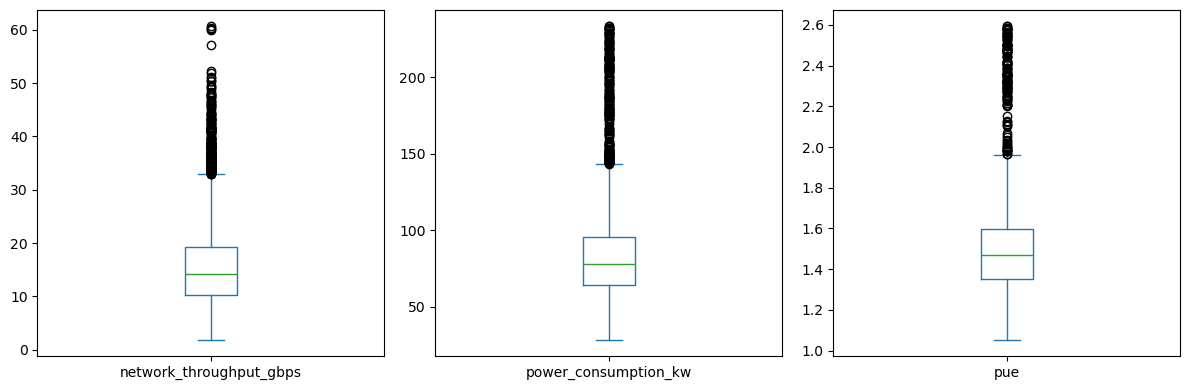

In [59]:
# Create boxplots for numeric columns to visualize outliers
columns_to_plot = ["network_throughput_gbps", "power_consumption_kw", "pue"]

df_clean[columns_to_plot].plot(kind="box", 
                               subplots=True, 
                               layout=(1, 3), 
                               figsize=(12, 4))

plt.tight_layout()
plt.show()

The boxplots confirmed the several high-end outliers, but the values reflect actual operating conditions rather than errors. They will be retained for further analysis since removing them could eliminate useful information about reduced efficiency and high energy consumption.

# Feature Engineering

## Goal - ##

### Determine whether we can create meaningful variables that help explain data center energy efficiency.

Investigate how the numerical variables relate to each other by viewing their correlations.

In [60]:
# Examine correlations between numerical variables
correlation_matrix = df_clean.corr(numeric_only=True) 

# Focus on relationships with PUE
correlation_matrix["pue"].sort_values(ascending=False) 

pue                        1.000000
inlet_temperature_c        0.343100
cpu_utilization            0.009624
workload_intensity         0.005935
carbon_emission_kg         0.001404
power_consumption_kw       0.000008
compute_cost_usd          -0.003455
network_throughput_gbps   -0.011869
memory_utilization        -0.016286
cooling_efficiency        -0.288593
Name: pue, dtype: float64

Lower PUE would indicate better energy efficiency, where strongly associated variables would drive us toward what features we can add.

Higher inlet temperatures tend to be associated with higher PUE, suggesting lower energy efficiency. Higher cooling efficiency tends to be associated with lower PUE, suggesting better efficiency. Lastly, workload intensity and CPU utilization show almost no direct linear relationship with PUE. Ultimately, the correlations do not tell us that changing temperature or cooling efficiency would cause PUE to change. The relationship between temperature and PUE might depend on how efficiently the cooling system operates, and we will create a new feature that explores the interaction between inlet temperature and cooling efficiency by multiplying the two variables. Do these two features provide extra predictive value?

In [61]:
# Create an interaction between temperature and cooling efficiency
df_clean["temperature_cooling_interaction"] = (df_clean["inlet_temperature_c"] * df_clean["cooling_efficiency"])

# Review the new feature
df_clean[["inlet_temperature_c", "cooling_efficiency", "temperature_cooling_interaction"]].head()

,inlet_temperature_c,cooling_efficiency,temperature_cooling_interaction
0,24.524,0.883,21.654692
1,21.944,0.951,20.868744
2,19.726,0.961,18.956686
3,20.036,0.959,19.214524
4,25.290,0.923,23.342670


In [62]:
# Compare correlations with PUE
df_clean[["inlet_temperature_c", "cooling_efficiency", "temperature_cooling_interaction", "pue"]].corr()["pue"]

inlet_temperature_c                0.343100
cooling_efficiency                -0.288593
temperature_cooling_interaction    0.149792
pue                                1.000000
Name: pue, dtype: float64

After comparing the correlations, I found that the temperature and cooling interaction had a weaker relationship with PUE (0.150) then inlet temperature (0.343) or cooling efficiency (-0.289) individually. While this feature might not improve model performance, it will be retained for consideration and later evaluation.

Next we will look at the categorical variables 

In [63]:
# Examine the categories in each categorical variable
categorical_cols = df_clean.select_dtypes(include="object").columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df_clean[col].value_counts(dropna=False))


server_type
server_type
Compute    4058
Storage    3055
GPU        1926
Edge        961
Name: count, dtype: int64

cooling_type
cooling_type
Air       4936
Liquid    3031
Hybrid    2033
Name: count, dtype: int64

datacenter_region
datacenter_region
Unknown    3990
EU         3056
APAC       1966
ME          988
Name: count, dtype: int64

time_of_day
time_of_day
Peak        4036
Off-Peak    3974
Night       1990
Name: count, dtype: int64

energy_efficiency_class
energy_efficiency_class
High      3400
Low       3300
Medium    3300
Name: count, dtype: int64


Our team selected energy efficiency classification as the primary modeling objective. Rather than predicting a continuous PUE value, we will compare classification algorithms to determine which model most effectively identifies different efficiency categories. I separated the target variable from the predictors and excluded PUE as a precaution against target leakage, since the efficiency categories may be based on PUE measurements.

In [64]:
# Define the classification target
y = df_clean["energy_efficiency_class"]

# Remove the target and potential leakage variable
X = df_clean.drop(columns=["energy_efficiency_class", "pue"])

# Check the dimensions
print("Predictors:", X.shape)
print("Target:", y.shape)

# Examine the target classes
print(y.value_counts())

Predictors: (10000, 14)
Target: (10000,)
energy_efficiency_class
High      3400
Low       3300
Medium    3300
Name: count, dtype: int64


The distribution of the three enegry classes showed to be nearly balanced, with 34% classified as High, with Medium and Low each at 33%. No class is substanstially underrepresented, so resampling is not necessary at this stage. Stratified partition will be used to preserve these proportions in the training and testing datasets.

The data must be partitioned before scaling/encoding.

In [65]:
from sklearn.model_selection import train_test_split

# Split data while preserving class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True))

Training set: (8000, 14)
Testing set: (2000, 14)

Training class distribution:
energy_efficiency_class
High      0.34
Medium    0.33
Low       0.33
Name: proportion, dtype: float64


Now that the stratified split preserved the original class proportions, we need to identify which predictors belong in each group.

In [66]:
# Identify numerical and categorical predictors
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['workload_intensity', 'cpu_utilization', 'memory_utilization', 'network_throughput_gbps', 'inlet_temperature_c', 'cooling_efficiency', 'power_consumption_kw', 'carbon_emission_kg', 'compute_cost_usd', 'temperature_cooling_interaction']

Categorical features:
['server_type', 'cooling_type', 'datacenter_region', 'time_of_day']


In [67]:
# Create preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[("num", StandardScaler(), numeric_features),
                  ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])
print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In order to ensure future models receive consistent data, a preprocessing pipeline was created. StandardScaler was selected because numerical variables have different measurement scales, while OneHotEncoder converts categorical values into a format suitable for machine learning. Using ColumnTransformer allows these transformations to be applied consistently across the dataset and reused when comparing classification algorithms.

We must check if some variables are calulated from power consumption or other measurements to prevent misleading model performance.

### Fit and Transform the Training Data

In [68]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to testing data
X_test_processed = preprocessor.transform(X_test)

# Check the resulting dimensions
print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)

# Retrieve the names of the transformed features
feature_names = preprocessor.get_feature_names_out()

# Display the feature names
for name in feature_names:
    print(name)

Training data: (8000, 24)
Testing data: (2000, 24)
num__workload_intensity
num__cpu_utilization
num__memory_utilization
num__network_throughput_gbps
num__inlet_temperature_c
num__cooling_efficiency
num__power_consumption_kw
num__carbon_emission_kg
num__compute_cost_usd
num__temperature_cooling_interaction
cat__server_type_Compute
cat__server_type_Edge
cat__server_type_GPU
cat__server_type_Storage
cat__cooling_type_Air
cat__cooling_type_Hybrid
cat__cooling_type_Liquid
cat__datacenter_region_APAC
cat__datacenter_region_EU
cat__datacenter_region_ME
cat__datacenter_region_Unknown
cat__time_of_day_Night
cat__time_of_day_Off-Peak
cat__time_of_day_Peak


I fitted the preprocessing pipeline using only the training data, then applied the same transformations to the testing data. This ensures that scaling parameters and categorical encodings are learned without using information from the test set. The resulting datasets can now be used consistently across the classification models.

The number of predictors increased from 14 to 24 because one-hot encoding created additional columns for the categorical variables. Both the training and testing datasets now contain the same 24 features.

Next, we will determine whether PUE completely determines the efficiency class by examining the PUE ranges for each class. If every High-efficiency observation has a lower PUE than every Medium-efficiency observation, and every Medium observation has a lower PUE than every Low observation, that would suggest the classes may have been assigned using PUE thresholds. Understanding this relationship is important because including variables that reveal the target could lead to misleadingly high model performance.

In [69]:
# Examine PUE values across efficiency classes
df_clean.groupby("energy_efficiency_class")["pue"].agg(["min", "max", "mean", "count"])

,min,max,mean,count
energy_efficiency_class,,,,
High,1.050,2.587,1.296999,3400
Low,1.395,2.574,1.668569,3300
Medium,1.280,2.596,1.481611,3300


Based on the table above, High-efficiency data centers have the lowest average PUE, while the low efficiency data centers have the highest. The PUE ranges also overlap, indicating that the classes cannot be separated perfectly using simple PUE thresholds. We will need to see if classes differ substantially across other numerical variables.

In [70]:
# Compare average numerical values across efficiency classes
class_summary = df_clean.groupby("energy_efficiency_class")[numeric_features].mean().T
class_summary.round(3)

energy_efficiency_class,High,Low,Medium
workload_intensity,0.547,0.546,0.549
cpu_utilization,46.207,46.376,46.426
memory_utilization,65.568,65.664,65.943
network_throughput_gbps,15.409,15.479,15.524
inlet_temperature_c,20.303,23.777,22.074
cooling_efficiency,0.918,0.801,0.862
power_consumption_kw,81.983,82.636,81.660
carbon_emission_kg,33.189,33.380,32.796
compute_cost_usd,10.102,10.157,10.135
temperature_cooling_interaction,18.616,19.064,19.036


After comparing the numerical variables across the three efficiency classes, I found that inlet temperature and cooling efficiency showed the most noticeable differences. The high-efficiency group had an average inlet temperature of 20.30°C, compared to 22.07°C for the medium group and 23.78°C for the low group. Cooling efficiency followed the opposite pattern, decreasing from 0.918 in the high-efficiency group to 0.862 and 0.801 in the medium- and low-efficiency groups. Meanwhile, power consumption remained relatively similar across all three groups, averaging around 82 kW. These results suggest that temperature and cooling efficiency may be more useful for distinguishing efficiency classes than overall power consumption, although we will need to evaluate their predictive value through model comparisons.

In [71]:
# Check for missing values after preprocessing
print("Missing values in training data:", np.isnan(X_train_processed).sum())

print("Missing values in testing data:", np.isnan(X_test_processed).sum())

# Confirm both datasets contain the same number of features
print("Training features:", X_train_processed.shape[1])
print("Testing features:", X_test_processed.shape[1])

Missing values in training data: 0
Missing values in testing data: 0
Training features: 24
Testing features: 24


After applying the preprocessing pipeline, I verified that both the training and testing datasets contained 24 features with no missing values. The numerical variables were standardized, and the categorical variables were converted into numerical indicators using one-hot encoding. The transformations were fitted using only the training data to avoid introducing information from the test set. These results confirm that the data has been prepared consistently for the classification models our team will compare.

In [72]:
# Create a folder for saved preprocessing objects
Path("models").mkdir(exist_ok=True)

# Save the fitted preprocessor
joblib.dump(preprocessor, "models/preprocessor.joblib")

print("Preprocessor saved.")

Preprocessor saved.


Preprocessor contains transformations fitted to the current training split. It can be reused for that split, but if used for cross-validation, preprocessing should be fitted separately within each training fold.

### Building Models and Hyperparameter Tuning
Initial models will be evaluated against a naive majority-class baseline. Because the High energy efficiency class represents the largest proportion of observations, a model that always predicts this class would achieve a baseline accuracy of approximately 34%. The final selected model must outperform this baseline and its competitors. They all must demonstrate that they provide value beyond simply predicting the most frequent class.
The following section fits and evaluates several classification algorithms using appropriate hyperparameters to identify models with promising predictive performance.

In [73]:
# Logistic Regression - basic baseline model
lr = LogisticRegression(max_iter=2000, random_state=42)

# Fit on pre-processed data
lr.fit(X_train_processed, y_train)
y_pred_lr = lr.predict(X_test_processed)

# Classification Metrics
print("LR Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

# Save lr model
joblib.dump(lr, "models/lr.joblib")
print("Logistic Regression model saved.")

LR Accuracy: 0.5505
              precision    recall  f1-score   support

        High       0.60      0.64      0.62       680
         Low       0.61      0.65      0.63       660
      Medium       0.41      0.36      0.39       660

    accuracy                           0.55      2000
   macro avg       0.54      0.55      0.54      2000
weighted avg       0.54      0.55      0.55      2000

Logistic Regression model saved.


The baseline logistic regression model appears to have a weak to moderate overall accuracy. Its precision, recall, and f1-sccore are relatively low for the medium energy efficiency class despite the support being similar to other classes. Recall is considerably weak; the model fails to identify 64% of the true medium energy efficiency cases. Hyperparameter tuning can be implemented on this model to see if we can retain higher scores.

In [74]:
# Hyperparameter tune LR
# Create pipeline
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Hyperparameters to test
param_grid_lr = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs", "saga"],
    "classifier__penalty": ["l2"]
}

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid search
lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid_lr,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit on original, unprocessed training data
lr_grid.fit(X_train, y_train)

print("Best parameters:", lr_grid.best_params_)
print("Best CV macro F1:", lr_grid.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'classifier__C': 100, 'classifier__penalty': 'l2', 'classifier__solver': 'lbfgs'}
Best CV macro F1: 0.5497034420344086


In [75]:
# Random Forest 
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
rf.fit(X_train_processed, y_train)
y_pred_rf = rf.predict(X_test_processed)

# Classification Metrics
print("RF Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

RF Accuracy: 0.5485
              precision    recall  f1-score   support

        High       0.61      0.64      0.63       680
         Low       0.58      0.64      0.61       660
      Medium       0.42      0.37      0.39       660

    accuracy                           0.55      2000
   macro avg       0.54      0.55      0.54      2000
weighted avg       0.54      0.55      0.54      2000



Random forest performed slightly worse than the logistic regression model as it had a lower recall for the medium class as well as the accuracy. It also predicted a smaller proportion of true positives for the low class, bringing the f-1 score down for low energy efficiency predictions. Across both models, the medium class appears to be a challenge in distinguishing from other classes. RF will be tuned below. 

In [76]:
# RF Hyperparameter tuning

# Create separate preprocessing pipeline for RF instead of using preprocessed predictors -- reduce data leakage
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf)
])

# Define parameters
param_grid_rf = {
    "classifier__n_estimators": [100, 200, 400],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5],
    "classifier__max_features": ["sqrt", 0.5]
}

# Cross validation with 5 folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid search using rf pipeline, parameter grid, and cv
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Apply pipeline and grid search to original data
rf_grid.fit(X_train, y_train)


print("Best parameters:", rf_grid.best_params_)
print("Best CV macro F1:", rf_grid.best_score_)

# Evaluate the tuned model on the held-out test set
best_rf = rf_grid.best_estimator_
y_pred_rf_tuned = best_rf.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred_rf_tuned))
print(classification_report(y_test, y_pred_rf_tuned))

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best parameters: {'classifier__max_depth': 10, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}
Best CV macro F1: 0.5496746819367779
Test accuracy: 0.5525
              precision    recall  f1-score   support

        High       0.61      0.65      0.63       680
         Low       0.61      0.63      0.62       660
      Medium       0.41      0.38      0.40       660

    accuracy                           0.55      2000
   macro avg       0.55      0.55      0.55      2000
weighted avg       0.55      0.55      0.55      2000



The best hyperparameter testing results only improved the model slightly. Medium class remains the lowest performance with not much improvement. These results are slightly better than the original logistic regression model. Train and test set results will be compared.

In [77]:
# Compare test and train sets
train_pred_rf = best_rf.predict(X_train)
print("Training accuracy:", accuracy_score(y_train, train_pred_rf))
print("Train macro F1:",f1_score(y_train, train_pred_rf, average="macro"))
print("Test accuracy:", accuracy_score(y_test, y_pred_rf))
print("Best Test CV macro F1:", rf_grid.best_score_)

Training accuracy: 0.75975
Train macro F1: 0.7577117595350273
Test accuracy: 0.5485
Best Test CV macro F1: 0.5496746819367779


The test accuracy is much lower than the training accuracy which may indicate overfitting. We will test another set of hyperparameters to see if more regularization improve the test results. 

In [78]:
# Try a different set of parameters
param_grid_rf = {
    "classifier__n_estimators": [200, 400],
    "classifier__max_depth": [3, 5, 8],
    "classifier__min_samples_split": [20, 50, 100],
    "classifier__min_samples_leaf": [10, 20, 40],
    "classifier__max_features": ["sqrt", 0.5]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
) 

# Apply pipeline and grid search to original data
rf_grid.fit(X_train, y_train)


print("Best parameters:", rf_grid.best_params_)
print("Best CV macro F1:", rf_grid.best_score_)

# Evaluate the tuned model on the held-out test set
best_rf = rf_grid.best_estimator_
y_pred_rf_tuned = best_rf.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred_rf_tuned))
print(classification_report(y_test, y_pred_rf_tuned))

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters: {'classifier__max_depth': 5, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 40, 'classifier__min_samples_split': 100, 'classifier__n_estimators': 200}
Best CV macro F1: 0.5535106273296555
Test accuracy: 0.552
              precision    recall  f1-score   support

        High       0.61      0.64      0.63       680
         Low       0.61      0.65      0.63       660
      Medium       0.41      0.36      0.39       660

    accuracy                           0.55      2000
   macro avg       0.54      0.55      0.55      2000
weighted avg       0.54      0.55      0.55      2000



After testing a wider range of hyperparameters, the f1 score slightly improved with a higher score on the low class, but the overall accuracy is a little lower. We can observe the confusion matrix to better understand the lower scores for the medium class.

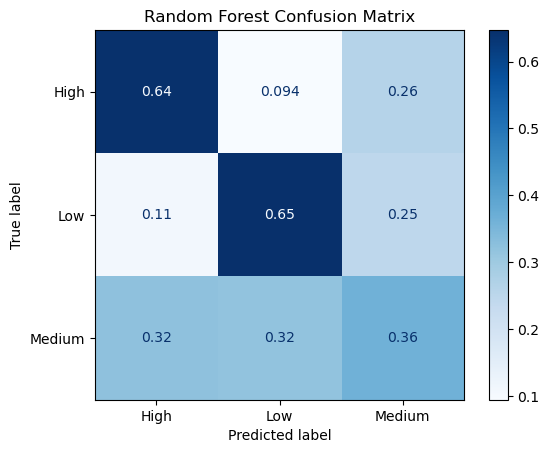

In [79]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf_tuned,
    labels=["High", "Low", "Medium"],
    normalize="true",
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

The confusion matrix shows relatively strong predictive power on low and high efficiency classes, but only 36% of the medium class is correctly identified. 

We will introduce another tree-based model below and compare the results. 

In [80]:
# XGBoost

# Encode the target labels as integers
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)

# Create the XGBoost pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=1
    ))
])

# Define hyperparameters to test
param_grid_xgb = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 6],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__subsample": [0.8, 1.0]
}

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for the best hyperparameters
xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid_xgb,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit using the original, unprocessed features
xgb_grid.fit(X_train, y_train_encoded)

print("Best parameters:", xgb_grid.best_params_)
print("Best CV macro F1:", xgb_grid.best_score_)


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100, 'classifier__subsample': 0.8}
Best CV macro F1: 0.5509726766677354


This model does not show much higher results than the others. We will add PUE that was initially dropped from the predictor list to see if this improves the results.

In [81]:
# See if re-adding PUE will change the model results:
X = df_clean.drop(columns=["energy_efficiency_class"])
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
display(X.columns)

# Ensure that the correct predictors are fit in the preprocessor
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[("num", StandardScaler(), numeric_features),
                  ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])

# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to testing data
X_test_processed = preprocessor.transform(X_test)

# Re-fit on pre-processed data
lr.fit(X_train_processed, y_train)
y_pred_lr = lr.predict(X_test_processed)

# Classification Metrics
print("LR Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

Index(['server_type', 'cooling_type', 'datacenter_region', 'time_of_day',
       'workload_intensity', 'cpu_utilization', 'memory_utilization',
       'network_throughput_gbps', 'inlet_temperature_c', 'cooling_efficiency',
       'power_consumption_kw', 'carbon_emission_kg', 'compute_cost_usd', 'pue',
       'temperature_cooling_interaction'],
      dtype='object')

LR Accuracy: 0.942
              precision    recall  f1-score   support

        High       0.97      0.97      0.97       680
         Low       0.96      0.91      0.94       660
      Medium       0.89      0.95      0.92       660

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000



Re-setting the x variables to add PUE significantly improved the baseline model results. This suggests that power usage effectiveness is an important predictor for energy efficiency level whose relationship cannot be captured by other variables. We will re-fit the other models and compare the results. 

In [82]:
# XGBoost

# Encode the target labels as integers
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Create the XGBoost pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=1
    ))
])

# Define hyperparameters to test
param_grid_xgb = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 6],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__subsample": [0.8, 1.0]
}

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Search for the best hyperparameters
xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid_xgb,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit using the original, unprocessed features
xgb_grid.fit(X_train, y_train_encoded)

print("Best parameters:", xgb_grid.best_params_)
print("Best CV macro F1:", xgb_grid.best_score_)

# Evaluate the tuned model on the held-out test set
best_xgb = xgb_grid.best_estimator_
y_pred_xgb_tuned = best_xgb.predict(X_test)

print("Test accuracy:", accuracy_score(y_test_encoded, y_pred_xgb_tuned))
print(classification_report(y_test_encoded, y_pred_xgb_tuned))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 6, 'classifier__n_estimators': 100, 'classifier__subsample': 0.8}
Best CV macro F1: 0.9835842881492256
Test accuracy: 0.9865
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       680
           1       0.99      0.98      0.99       660
           2       0.98      0.99      0.98       660

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



In [83]:
# RF Hyperparameter tuning

# Create separate preprocessing pipeline for RF instead of using preprocessed predictors -- reduce data leakage
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf)
])

# Define parameters
param_grid_rf = {
    "classifier__n_estimators": [100, 200, 400],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_leaf": [1, 2, 5],
    "classifier__max_features": ["sqrt", 0.5]
}

# Cross validation with 5 folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid search using rf pipeline, parameter grid, and cv
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Apply pipeline and grid search to original data
rf_grid.fit(X_train, y_train)


print("Best parameters:", rf_grid.best_params_)
print("Best CV macro F1:", rf_grid.best_score_)

# Evaluate the tuned model on the held-out test set
best_rf = rf_grid.best_estimator_
y_pred_rf_tuned = best_rf.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred_rf_tuned))
print(classification_report(y_test, y_pred_rf_tuned))

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 0.5, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 400}
Best CV macro F1: 0.9805842893899337
Test accuracy: 0.9825
              precision    recall  f1-score   support

        High       0.99      0.98      0.99       680
         Low       0.98      0.98      0.98       660
      Medium       0.97      0.98      0.98       660

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



### Results and Final Model Selection
Logistic regression showed promising metrics, however, random forest and xgboost showed better predictive capabilities across all classes whereas lr comparatively fell short on predicting low and medium classes. Therefore, XGboost and RF will be evaluated as the final models. 

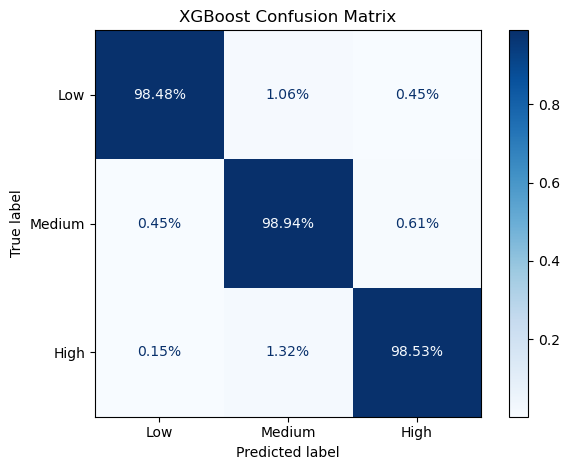

XGBoost Test accuracy: 0.9865
              precision    recall  f1-score   support

        High       0.99      0.99      0.99       680
         Low       0.99      0.98      0.99       660
      Medium       0.98      0.99      0.98       660

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



In [84]:
# Create confusion matrix for XGBoost

class_names = ["Low", "Medium", "High"]

cm = confusion_matrix(
    y_test_encoded,
    y_pred_xgb_tuned,
    labels=label_encoder.transform(class_names),
    normalize="true"
)

# Plot
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap="Blues", values_format=".2%")
plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.show()

print("XGBoost Test accuracy:", accuracy_score(y_test_encoded, y_pred_xgb_tuned))
print(classification_report(y_test_encoded, y_pred_xgb_tuned, target_names=label_encoder.classes_))

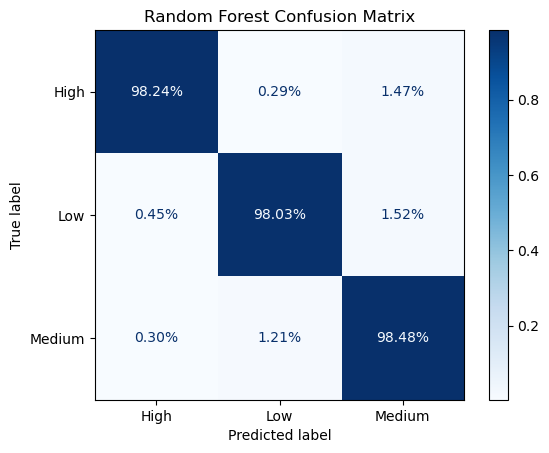

RF Test accuracy: 0.9825
              precision    recall  f1-score   support

        High       0.99      0.98      0.99       680
         Low       0.98      0.98      0.98       660
      Medium       0.97      0.98      0.98       660

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



In [71]:
# Random Forest Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf_tuned,
    labels=["High", "Low", "Medium"],
    normalize="true",
    cmap="Blues",
    values_format=".2%"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

print("RF Test accuracy:", accuracy_score(y_test, y_pred_rf_tuned))
print(classification_report(y_test, y_pred_rf_tuned))

Both models performed very well when PUE was re-introduced as a predictor. They similarly have the highest recall on the high efficiency class. However, XGBoost performs slightly better as the macro average f1 score is the highest, where the harmonic mean of recall and precision is higher than that of the Random Forest model. 
Low energy efficiency - RF correctly identifies 98.03% of low efficiency data centers. 1.52% of them are incorrectly classified as medium, and only 0.45% are classified as high which is the lowest and most reasonable metric for this class. XGBoost correctly identifies a larger proportion at 98.48%, and a much smaller proportion of low energy facilities are incorrectly classified as high (only 0.3%).
Medium energy efficiency - RF correctly identifies 98.48% of the true medium class; most of the incorrectly classified records were predicted as low (1.21%). XGBoost performs better on this class as only 0.91% of all medium energy efficiency facilities are incorrectly classified.
High energy efficiency - RF shows a recall of 98.24%. Most of the wrongly predicted records were classified as medium instead of low, which is a good sign. For XGBoost with a recall of 98.68% (the highest of all classes), only 0.15% of high were wrongly predicted as low. 

Despite XGBoost showing promising results, careful consideration must be drawn to the false positive predictions. For instance, for the low energy efficiency class, it only wrongly predicted 0.30% of all records as high efficiency. While this proportion is very small and seems insignificant, this represents 30 facilties who could be led down the wrong path. Small errors such as these could have a serious impact on the quality control and evaluation process. Therefore, futher investigation of how to properly weigh the variables to account for these errors should be done in the future. 

Final model selection: XGBoost 
Best parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 6, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}

In [76]:
# 95% Confidence Interval 

# Make sure that predictions and true labels are in the same format
y_true = np.asarray(y_test)
y_pred = np.asarray(y_pred_xgb_tuned)

# Decode predictions before calculating accuracy:
y_pred = label_encoder.inverse_transform(y_pred.astype(int))

correct = np.sum(y_true == y_pred)
n = len(y_true)

accuracy = correct / n
lower, upper = proportion_confint(
    count=correct,
    nobs=n,
    alpha=0.05,
    method="wilson"
)

print(f"XGBoost Test accuracy: {accuracy:.2%}")
print(f"95% confidence interval: {lower:.2%} to {upper:.2%}")

Test accuracy: 98.65%
95% confidence interval: 98.04% to 99.07%
